In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully.")


Mounted at /content/drive
Google Drive mounted successfully.


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/AML_Project"

OUTPUT_PATH = os.path.join(
    PROJECT_PATH,
    "outputs"
)

FORENSIC_PATH = os.path.join(
    OUTPUT_PATH,
    "forensic"
)

FA03_PATH = os.path.join(
    FORENSIC_PATH,
    "FA03"
)

os.makedirs(FA03_PATH, exist_ok=True)

print("FA03 output folder:")
print(FA03_PATH)

FA03 output folder:
/content/drive/MyDrive/AML_Project/outputs/forensic/FA03


In [ ]:
TRANSACTION_FILE = os.path.join(
    OUTPUT_PATH,
    "integrated_transaction_risk_results.csv"
)

df = pd.read_csv(TRANSACTION_FILE)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (149994, 35)


In [ ]:
exact_duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", exact_duplicate_count)

Exact duplicate rows: 0


In [ ]:
duplicate_keys = [
    "sender",
    "receiver",
    "amount",
    "transaction_type"
]

df["transaction_signature_count"] = (
    df.groupby(duplicate_keys)["transaction_id"]
      .transform("count")
)

repeated_transactions = df[
    df["transaction_signature_count"] > 1
].copy()

print(
    "Transactions belonging to repeated signatures:",
    len(repeated_transactions)
)

Transactions belonging to repeated signatures: 16


In [ ]:
repeated_summary = (
    repeated_transactions
    .groupby(duplicate_keys)
    .agg(
        repetition_count=("transaction_id", "count"),
        fraud_count=("is_fraud", "sum")
    )
    .reset_index()
    .sort_values(
        "repetition_count",
        ascending=False
    )
)

display(repeated_summary.head(20))

,sender,receiver,amount,transaction_type,repetition_count,fraud_count
0,CUST00219,MER00238,7086.0,Bills,2,0
1,CUST00568,MER00196,2824.0,Fuel,2,0
2,CUST02268,MER00116,1564.0,Food,2,0
3,CUST03408,MER00214,3795.0,Bills,2,0
4,CUST03804,MER00006,9315.0,Shopping,2,0
5,CUST04107,MER00106,1012.0,Food,2,0
6,CUST04226,MER00164,1463.0,Fuel,2,0
7,CUST04915,MER00117,969.0,Food,2,0


In [ ]:
repeated_transactions.to_csv(
    os.path.join(
        FA03_PATH,
        "repeated_transactions.csv"
    ),
    index=False
)

repeated_summary.to_csv(
    os.path.join(
        FA03_PATH,
        "repeated_transaction_summary.csv"
    ),
    index=False
)

print("Saved repeated transaction outputs.")

Saved repeated transaction outputs.


In [ ]:
amount_series = df["amount"].dropna()

Q1 = amount_series.quantile(0.25)
Q3 = amount_series.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")

Q1: 3023.00
Q3: 19272.75
IQR: 16249.75
Lower Bound: -21351.62
Upper Bound: 43647.38


In [ ]:
amount_outliers = df[
    (df["amount"] < lower_bound) |
    (df["amount"] > upper_bound)
].copy()

amount_outliers["amount_outlier_flag"] = 1

print(
    "Amount outlier transactions:",
    len(amount_outliers)
)

Amount outlier transactions: 16681


In [ ]:
outlier_fraud_count = amount_outliers["is_fraud"].sum()

outlier_fraud_rate = (
    amount_outliers["is_fraud"].mean() * 100
    if len(amount_outliers) > 0
    else 0
)

overall_fraud_rate = (
    df["is_fraud"].mean() * 100
)

print("Amount outliers:", len(amount_outliers))
print("Fraud among outliers:", outlier_fraud_count)
print(f"Fraud rate among outliers: {outlier_fraud_rate:.2f}%")
print(f"Overall fraud rate: {overall_fraud_rate:.2f}%")

Amount outliers: 16681
Fraud among outliers: 1085
Fraud rate among outliers: 6.50%
Overall fraud rate: 0.97%


In [ ]:
top_amount_outliers = (
    amount_outliers
    .sort_values(
        "amount",
        ascending=False
    )
)

display(
    top_amount_outliers[
        [
            "transaction_id",
            "sender",
            "receiver",
            "amount",
            "transaction_type",
            "timestamp",
            "city",
            "fraud_type",
            "is_fraud",
            "integrated_risk_score"
        ]
    ].head(20)
)

,transaction_id,sender,receiver,amount,transaction_type,timestamp,city,fraud_type,is_fraud,integrated_risk_score
43856,TX00069979,CUST01436,CUST00008,999431.0,RTGS,2026-01-04 20:47:47,Coimbatore,Normal,0,0.0
30313,TX00025379,CUST00985,CUST03626,999344.0,RTGS,2026-01-02 20:32:50,Lucknow,Normal,0,0.0
127717,TX00124338,CUST04246,CUST04093,999277.0,RTGS,2026-01-06 15:15:20,Indore,Normal,0,0.0
68132,TX00137069,CUST02248,CUST04111,999117.0,RTGS,2026-01-07 15:00:57,Kanpur,Normal,0,0.0
63461,TX00115186,CUST02095,CUST02162,998690.0,RTGS,2026-01-06 21:14:30,Nagpur,Normal,0,0.0
130031,TX00124682,CUST04328,CUST02416,998013.0,RTGS,2026-01-06 08:34:51,Coimbatore,Normal,0,0.0
127868,TX00060842,CUST04251,CUST02635,997734.0,RTGS,2026-01-03 13:37:18,Delhi,Normal,0,0.0
54282,TX00028830,CUST01786,CUST00535,997435.0,RTGS,2026-01-02 20:14:40,Hyderabad,Normal,0,0.0
109516,TX00058182,CUST03629,CUST03654,997361.0,RTGS,2026-01-03 15:54:25,Patna,Normal,0,0.0
33982,TX00111018,CUST01104,CUST04146,997338.0,RTGS,2026-01-06 22:14:00,Patna,Normal,0,0.0


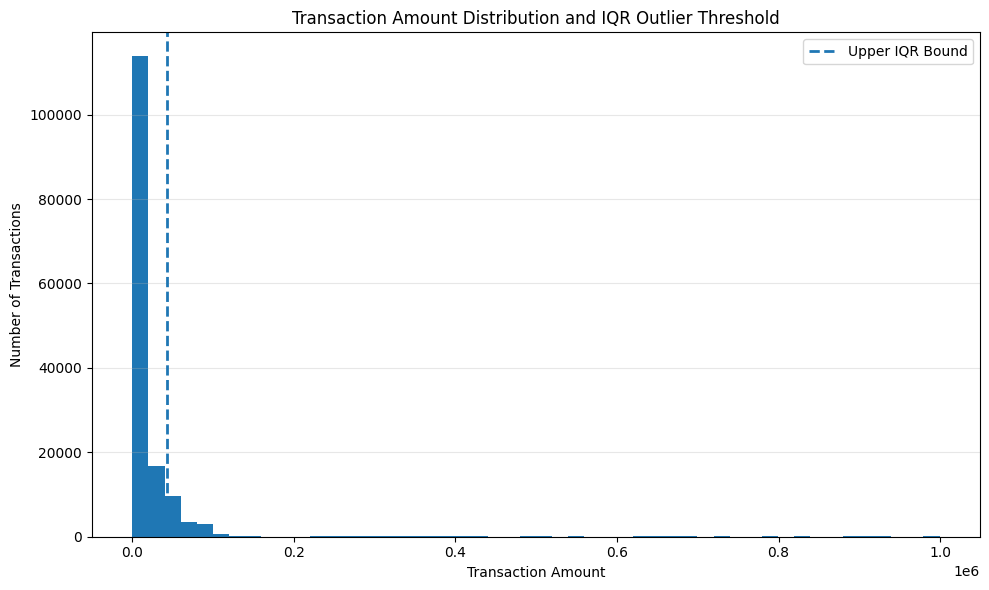

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["amount"],
    bins=50
)

plt.axvline(
    upper_bound,
    linestyle="--",
    linewidth=2,
    label="Upper IQR Bound"
)

plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.title("Transaction Amount Distribution and IQR Outlier Threshold")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FA03_PATH,
        "transaction_amount_outliers.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
outlier_comparison = pd.DataFrame({
    "group": [
        "All Transactions",
        "Amount Outliers"
    ],
    "transaction_count": [
        len(df),
        len(amount_outliers)
    ],
    "fraud_count": [
        int(df["is_fraud"].sum()),
        int(amount_outliers["is_fraud"].sum())
    ],
    "fraud_rate_percent": [
        df["is_fraud"].mean() * 100,
        amount_outliers["is_fraud"].mean() * 100
        if len(amount_outliers) > 0 else 0
    ]
})

display(outlier_comparison)

,group,transaction_count,fraud_count,fraud_rate_percent
0,All Transactions,149994,1450,0.966705
1,Amount Outliers,16681,1085,6.504406


In [ ]:
df["repeated_transaction_flag"] = (
    df["transaction_signature_count"] > 1
).astype(int)

df["amount_outlier_flag"] = (
    (df["amount"] < lower_bound) |
    (df["amount"] > upper_bound)
).astype(int)

df["forensic_anomaly_count"] = (
    df["repeated_transaction_flag"] +
    df["amount_outlier_flag"]
)

print("Forensic anomaly flags created.")

Forensic anomaly flags created.


In [ ]:
anomaly_distribution = (
    df["forensic_anomaly_count"]
    .value_counts()
    .sort_index()
    .reset_index()
)

anomaly_distribution.columns = [
    "number_of_forensic_flags",
    "transaction_count"
]

display(anomaly_distribution)

,number_of_forensic_flags,transaction_count
0,0,133297
1,1,16697


In [ ]:
forensic_candidates = df[
    df["forensic_anomaly_count"] > 0
].copy()

forensic_candidates = forensic_candidates.sort_values(
    [
        "forensic_anomaly_count",
        "integrated_risk_score"
    ],
    ascending=[False, False]
)

display(
    forensic_candidates[
        [
            "transaction_id",
            "sender",
            "receiver",
            "amount",
            "transaction_type",
            "timestamp",
            "city",
            "fraud_type",
            "is_fraud",
            "repeated_transaction_flag",
            "amount_outlier_flag",
            "integrated_risk_score",
            "risk_category"
        ]
    ].head(30)
)


,transaction_id,sender,receiver,amount,transaction_type,timestamp,city,fraud_type,is_fraud,repeated_transaction_flag,amount_outlier_flag,integrated_risk_score,risk_category
774,FRAUD001374,CUST00028,CUST01480,82943.79,Transfer,2026-01-06 02:44:00,Mumbai,RapidGeographicMovement,1,0,1,100.0,High Risk
2883,FRAUD001278,CUST00096,CUST03001,60486.15,Transfer,2026-01-06 04:39:00,Hyderabad,RapidGeographicMovement,1,0,1,100.0,High Risk
4999,FRAUD001302,CUST00161,CUST02586,121086.62,Transfer,2026-01-06 15:22:00,Jaipur,RapidGeographicMovement,1,0,1,100.0,High Risk
5051,FRAUD001340,CUST00163,CUST01013,81203.41,Transfer,2026-01-06 03:05:00,Chennai,RapidGeographicMovement,1,0,1,100.0,High Risk
5053,FRAUD001342,CUST00163,CUST02308,123781.53,Transfer,2026-01-06 03:19:00,Hyderabad,RapidGeographicMovement,1,0,1,100.0,High Risk
10960,FRAUD001365,CUST00354,CUST01947,134157.91,Transfer,2026-01-06 04:33:00,Kolkata,RapidGeographicMovement,1,0,1,100.0,High Risk
11292,TX00022768,CUST00366,CUST02628,44229.00,Transfer,2026-01-02 13:22:27,Bengaluru,Normal,0,0,1,100.0,High Risk
13039,FRAUD001325,CUST00423,CUST04245,118753.23,Transfer,2026-01-06 06:02:00,Chennai,RapidGeographicMovement,1,0,1,100.0,High Risk
18230,FRAUD001446,CUST00572,CUST03573,130542.03,Transfer,2026-01-06 17:54:00,Jaipur,RapidGeographicMovement,1,0,1,100.0,High Risk
19100,TX00108961,CUST00602,CUST01922,44538.00,Transfer,2026-01-06 21:11:59,Kolkata,Normal,0,0,1,100.0,High Risk


In [ ]:
candidate_count = len(forensic_candidates)

candidate_fraud_count = (
    forensic_candidates["is_fraud"].sum()
)

candidate_fraud_rate = (
    candidate_fraud_count / candidate_count * 100
    if candidate_count > 0
    else 0
)

print("Forensic candidates:", candidate_count)
print("Ground-truth fraud among candidates:", candidate_fraud_count)
print(
    f"Fraud rate among forensic candidates: "
    f"{candidate_fraud_rate:.2f}%"
)

Forensic candidates: 16697
Ground-truth fraud among candidates: 1085
Fraud rate among forensic candidates: 6.50%


In [ ]:
amount_outliers.to_csv(
    os.path.join(
        FA03_PATH,
        "amount_outliers.csv"
    ),
    index=False
)

top_amount_outliers.to_csv(
    os.path.join(
        FA03_PATH,
        "top_amount_outliers.csv"
    ),
    index=False
)

outlier_comparison.to_csv(
    os.path.join(
        FA03_PATH,
        "outlier_comparison.csv"
    ),
    index=False
)

anomaly_distribution.to_csv(
    os.path.join(
        FA03_PATH,
        "forensic_anomaly_distribution.csv"
    ),
    index=False
)

forensic_candidates.to_csv(
    os.path.join(
        FA03_PATH,
        "forensic_candidates.csv"
    ),
    index=False
)

print("All FA03 outputs saved successfully.")

All FA03 outputs saved successfully.


In [ ]:
fa03_summary = pd.DataFrame({
    "metric": [
        "Total transactions",
        "Exact duplicate rows",
        "Repeated-signature transactions",
        "Amount outlier transactions",
        "Forensic candidates",
        "Fraud among forensic candidates",
        "Overall fraud rate (%)",
        "Forensic candidate fraud rate (%)"
    ],
    "value": [
        len(df),
        exact_duplicate_count,
        len(repeated_transactions),
        len(amount_outliers),
        candidate_count,
        int(candidate_fraud_count),
        overall_fraud_rate,
        candidate_fraud_rate
    ]
})

display(fa03_summary)

fa03_summary.to_csv(
    os.path.join(
        FA03_PATH,
        "FA03_summary.csv"
    ),
    index=False
)

print("Saved: FA03_summary.csv")

,metric,value
0,Total transactions,149994.000000
1,Exact duplicate rows,0.000000
2,Repeated-signature transactions,16.000000
3,Amount outlier transactions,16681.000000
4,Forensic candidates,16697.000000
5,Fraud among forensic candidates,1085.000000
6,Overall fraud rate (%),0.966705
7,Forensic candidate fraud rate (%),6.498173


Saved: FA03_summary.csv


# FA_03 — Transaction Anomaly Analysis

## Financial Crime Analytics & Money Laundering Investigation Platform

### Objective

This notebook identifies unusual transaction-level behaviour using
duplicate detection, repeated transaction analysis and statistical
amount outlier detection.

### Forensic Techniques

1. Exact Duplicate Transaction Detection
2. Repeated Transaction Detection
3. Transaction Amount Outlier Detection using IQR
4. Comparison with Controlled Fraud Labels
5. Investigation-Oriented Anomaly Output

### Important Note

An anomaly does not automatically indicate fraud.

The detected transactions are treated as candidates for further forensic
investigation. Since the project uses a controlled synthetic dataset,
ground-truth fraud labels are used to evaluate the forensic indicators.